In [3]:
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs, make_gaussian_quantiles
import matplotlib.pyplot as plt

In [29]:
rand = 42
sample_amount = 40_000
feature_amount = 20

In [30]:
#dataset 1 (8 blobs)

X, cluster_id = make_blobs(n_samples=sample_amount, n_features=feature_amount, centers=8, cluster_std=1.2, random_state=rand,)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [26]:
#dataset 2 (1 cluster with correlated features)

mean = np.zeros(feature_amount)
cov = np.random.default_rng(rand).uniform(-0.5, 0.5, size=(feature_amount, feature_amount))
cov = cov @ cov.T
X = np.random.default_rng(rand).multivariate_normal(mean, cov, size=sample_amount)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [28]:
#dataset 3 (nested/ non-linear structure)

X, y = make_gaussian_quantiles(n_samples=sample_amount, n_features=feature_amount, n_classes=3, random_state=rand)
df = pd.DataFrame(X, columns=[f"f{i}" for i in range(X.shape[1])])

In [76]:
#1 | extreme        | push feature values far outside range
#2 | gaussian       | add jitter to feature values
#3 | shuffle        | swap feature values with other row's
#4 | uniform_random | replace feature values with values from data range (ignores correlation)

def inject_noise(df, noise_frac=0.1, method=1, n_features_affected=None, seed=rand):

    rng = np.random.default_rng(seed)
    noisy = df.copy()
    cols_all = df.columns
    n = len(df)
    n_noise = int(n * noise_frac)
    noise_idx = rng.choice(df.index, size=n_noise, replace=False)
    mask = np.zeros(n, dtype=bool)
    mask[df.index.get_indexer(noise_idx)] = True

    for row_id in noise_idx:
        if n_features_affected is None:
            cols = cols_all
        else:
            cols = rng.choice(cols_all, size=n_features_affected, replace=False)

        for col in cols:
            std = df[col].std()

            match method:
                case 1:
                    direction = rng.choice([-1, 1])
                    magnitude = rng.uniform(6, 12)
                    noisy.loc[row_id, col] = df.loc[row_id, col] + direction * std * magnitude

                case 2:
                    noisy.loc[row_id, col] = df.loc[row_id, col] + rng.normal(0, std * 3)

                case 3:
                    donor_id = rng.choice(df.index)
                    noisy.loc[row_id, col] = df.loc[donor_id, col]

                case 4:
                    lo, hi = df[col].min(), df[col].max()
                    noisy.loc[row_id, col] = rng.uniform(lo, hi)

                case _:
                    raise ValueError(f"Unknown method: {method}")

    return noisy, mask

In [77]:
noisy_df, true_mask = inject_noise(df, noise_frac=0.1, method=2)
#enable multiple noises (take truemask in and add to it)

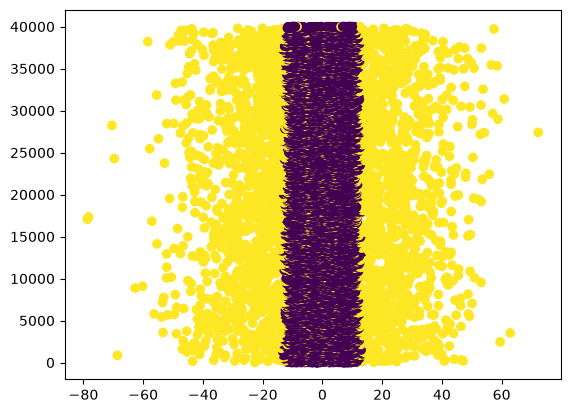

In [78]:
plt.scatter(noisy_df.iloc[:, 0], df.index, c=true_mask)
# plt.scatter(df.iloc[:, 0], df.index)
plt.scatter
plt.show()

In [79]:
#metaparam
iqr_mp = 1.5
col_ratio_mp = 0.8

suspects = np.zeros(len(noisy_df), dtype=int)
false_pos = 0
false_neg = 0

for col in noisy_df.columns:
    Q1 = np.percentile(noisy_df[col], 25)
    Q3 = np.percentile(noisy_df[col], 75)
    IQR = Q3 - Q1
    lower_bound_iqr = Q1 - iqr_mp * IQR
    upper_bound_iqr = Q3 + iqr_mp * IQR
    outliers = (noisy_df[col] < lower_bound_iqr) | (noisy_df[col] > upper_bound_iqr)
    suspects += outliers

purps = suspects > len(noisy_df.columns) * col_ratio_mp

for i in range(len(noisy_df)):
    if (true_mask[i] == True) and (true_mask[i] != purps[i]):
        false_neg += 1
    elif (true_mask[i] == False) and (true_mask[i] != purps[i]):
        false_pos += 1

print(false_neg)
print(false_pos)


4000
0
